# Лабораторная 1. Среда, данные и первая сводка

Задание целиком: `labs/lab01/README.md` в репозитории курса.

Как работать с ноутбуком:
1. В первой ячейке впишите свой номер варианта.
2. Заполните ячейки с пометкой `TODO` по порядку. Подсказки в комментариях.
3. В конце выполните Run All с нуля, скачайте ноутбук и `results.zip`.

Ноутбук работает в Kaggle, Colab и локально. В Kaggle включите интернет: правая панель → Settings → Internet → On. Если интернет в Kaggle включить нельзя, работайте в Colab или локально.

## 0. Установка и загрузка данных

Ячейка определяет, где запущен ноутбук, находит или скачивает `get_data.py` из репозитория курса и загружает ваш вариант. Ничего в ней менять не нужно, кроме `VARIANT`.

In [1]:
VARIANT = 17
DATA_SOURCE = None  # запасной путь: папка с архивами variant_NN.zip

import os
import sys
import inspect
import urllib.request
from pathlib import Path

assert isinstance(VARIANT, int) and 0 <= VARIANT <= 22, "Впишите свой номер варианта: целое число от 1 до 22"
if VARIANT == 0:
    print("ВНИМАНИЕ: вариант 00 демонстрационный, работа на нём не засчитывается")

if "google.colab" in sys.modules:
    ENV, DATA_ROOT = "colab", Path("/content/data")
elif Path("/kaggle/working").exists():
    ENV, DATA_ROOT = "kaggle", Path("/kaggle/working/data")
elif Path("../../data/get_data.py").exists():
    # Ноутбук открыт прямо из клона репозитория курса: данные кладём в его папку data/
    ENV, DATA_ROOT = "local", Path("../../data").resolve()
else:
    # Локально: ноутбук лежит в cv-2026-familiya/lab01/, данные кладём в cv-2026-familiya/data/.
    # Эта папка указана в .gitignore, в репозиторий она не попадёт.
    ENV, DATA_ROOT = "local", Path("..").resolve() / "data"
DATA_ROOT.mkdir(parents=True, exist_ok=True)
print("среда:", ENV, "| папка данных:", DATA_ROOT)

GET_DATA_URL = "https://raw.githubusercontent.com/ykvnkm/computer-vision-course/main/data/get_data.py"
course_copy = Path("../../data/get_data.py")
kaggle_copies = sorted(Path("/kaggle/input").glob("**/get_data.py")) if ENV == "kaggle" else []
if course_copy.exists():
    script_dir = course_copy.resolve().parent
elif kaggle_copies:
    # Kaggle с подключённым датасетом-зеркалом курса: интернет не нужен
    script_dir = kaggle_copies[0].parent
    print("get_data.py из подключённого датасета:", kaggle_copies[0])
else:
    script_dir = DATA_ROOT
    if not (script_dir / "get_data.py").exists():
        try:
            urllib.request.urlretrieve(GET_DATA_URL, script_dir / "get_data.py")
        except Exception as e:
            raise RuntimeError("Не удалось скачать get_data.py. В Kaggle включите Internet в Settings; "
                               "в остальных случаях проверьте подключение к сети.") from e
sys.path.insert(0, str(script_dir))
from get_data import ensure_variant

params = inspect.signature(ensure_variant).parameters
kwargs = {"dest": DATA_ROOT} if "dest" in params else {}
if DATA_SOURCE and "source" in params:
    kwargs["source"] = DATA_SOURCE
DATA_DIR = Path(ensure_variant(VARIANT, **kwargs))
print("данные варианта:", DATA_DIR)
print(sorted(p.name for p in DATA_DIR.iterdir()))

среда: local | папка данных: /Users/haiksarg/Desktop/computer-vision-course/cv-2026-sargsyan/data
Вариант 17 уже на месте: /Users/haiksarg/Desktop/computer-vision-course/cv-2026-sargsyan/data/variant_17


данные варианта: /Users/haiksarg/Desktop/computer-vision-course/cv-2026-sargsyan/data/variant_17
['.get_data.json', 'README.md', 'annotations', 'images', 'labels.csv', 'variant.json']


In [2]:
import json
import xml.etree.ElementTree as ET

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from PIL import Image

IMG_DIR = DATA_DIR / "images"
XML_DIR = DATA_DIR / "annotations" / "xmls"
TRIMAP_DIR = DATA_DIR / "annotations" / "trimaps"
RESULTS = Path("results")
RESULTS.mkdir(exist_ok=True)

print("OpenCV", cv2.__version__, "| numpy", np.__version__, "| pandas", pd.__version__)

OpenCV 4.14.0 | numpy 2.5.4 | pandas 3.1.0


## 1. Что лежит в папке варианта

Прочитайте `variant.json` и `labels.csv`. Проверьте, что номер варианта в `variant.json` совпадает с вашим.

In [3]:
variant_info = json.loads((DATA_DIR / "variant.json").read_text(encoding="utf-8"))
print(variant_info)

labels = pd.read_csv(DATA_DIR / "labels.csv")
labels.head()

{'variant': 17, 'dataset_version': 'v1', 'source': 'release', 'breeds': ['Bombay', 'Persian', 'chihuahua', 'miniature_pinscher'], 'species': {'Bombay': 'cat', 'Persian': 'cat', 'chihuahua': 'dog', 'miniature_pinscher': 'dog'}, 'class_ids': {'Bombay': 0, 'Persian': 1, 'chihuahua': 2, 'miniature_pinscher': 3}, 'names_ru': {'Bombay': 'бомбейская кошка', 'Persian': 'персидская кошка', 'chihuahua': 'чихуахуа', 'miniature_pinscher': 'цвергпинчер'}, 'n_images': 800, 'n_boxes': 400, 'n_trimaps': 800, 'per_breed': {'Bombay': {'images': 200, 'boxes': 100, 'trimaps': 200}, 'Persian': {'images': 200, 'boxes': 100, 'trimaps': 200}, 'chihuahua': {'images': 200, 'boxes': 100, 'trimaps': 200}, 'miniature_pinscher': {'images': 200, 'boxes': 100, 'trimaps': 200}}, 'dataset': 'Oxford-IIIT Pet', 'dataset_url': 'https://www.robots.ox.ac.uk/~vgg/data/pets/', 'license': 'CC BY-SA 4.0', 'citation': 'O. M. Parkhi, A. Vedaldi, A. Zisserman, C. V. Jawahar. Cats and Dogs. IEEE Conference on Computer Vision and Pa

,filename,breed,species,class_id
0,Bombay_1.jpg,Bombay,cat,0
1,Bombay_2.jpg,Bombay,cat,0
2,Bombay_3.jpg,Bombay,cat,0
3,Bombay_4.jpg,Bombay,cat,0
4,Bombay_5.jpg,Bombay,cat,0


## 2. Изображение как массив

Возьмите одно изображение и посмотрите, что вернул OpenCV. Выберите файл, который Pillow определяет как `JPEG` в режиме `RGB`: необычные файлы разберём в разделе 3.

In [4]:
# Выбираем самое «цветное» фото среди 100 случайных обычных JPEG: на нём ошибка BGR/RGB заметнее
best, best_score = None, -1.0
for fn in labels["filename"].sample(frac=1, random_state=0).head(100):
    with Image.open(IMG_DIR / fn) as im:
        if im.format != "JPEG" or im.mode != "RGB":
            continue
        arr = np.asarray(im.resize((64, 64)), dtype=np.float32)[16:48, 16:48]  # центр кадра
    score = float(np.abs(arr[..., 0] - arr[..., 2]).mean())
    if score > best_score:
        best, best_score = fn, score
example_name = best
example_path = IMG_DIR / example_name
print(example_name)


bgr = cv2.imread(str(example_path))
print(type(bgr), bgr.shape, bgr.dtype, bgr.min(), bgr.max())
print(bgr[bgr.shape[0] // 2, bgr.shape[1] // 2])

miniature_pinscher_74.jpg
<class 'numpy.ndarray'> (500, 344, 3) uint8 0 255
[ 18  31 109]


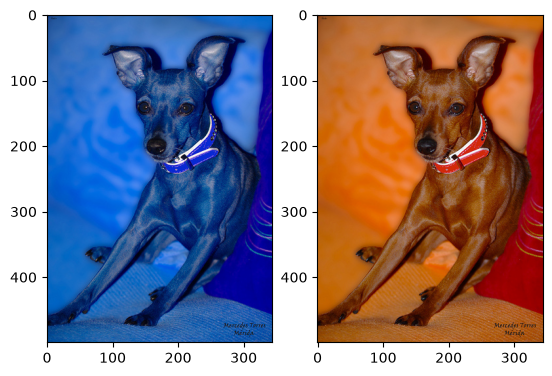

In [5]:
rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
plt.subplot(1, 2, 1); plt.imshow(bgr)
plt.subplot(1, 2, 2); plt.imshow(rgb)
plt.show()

Преобразования. Подсказки:

| Что | Функция |
|---|---|
| оттенки серого | `cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)` |
| ресайз | `cv2.resize(rgb, (224, 224))` |
| отражение | `cv2.flip(rgb, 1)` |

In [6]:
gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
resized = cv2.resize(rgb, (224, 224))
flipped = cv2.flip(rgb, 1)
print(gray.shape, resized.shape, flipped.shape)

(500, 344) (224, 224, 3) (500, 344, 3)


In [7]:
# Ловушка uint8: запустите и посмотрите, что получилось
a = np.array([[50, 200, 250]], dtype=np.uint8)   # «картинка» 1x3 пикселя
print("numpy a + 100:", a + 100)
print("cv2.add:      ", cv2.add(a, np.full_like(a, 100)))

numpy a + 100: [[150  44  94]]
cv2.add:       [[150 255 255]]


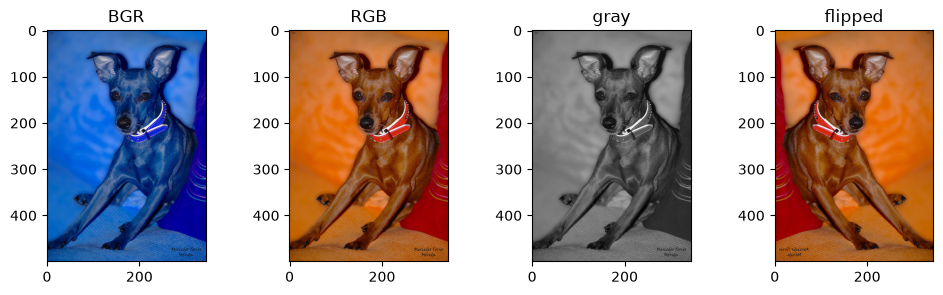

In [8]:
plt.figure(figsize=(12, 3))
plt.subplot(1, 4, 1); plt.imshow(bgr); plt.title("BGR")
plt.subplot(1, 4, 2); plt.imshow(rgb); plt.title("RGB")
plt.subplot(1, 4, 3); plt.imshow(gray, cmap="gray"); plt.title("gray")
plt.subplot(1, 4, 4); plt.imshow(flipped); plt.title("flipped")
plt.savefig(RESULTS / "transforms.png", dpi=110)
plt.show()

## 3. Сводка по датасету

Пройдите по всем файлам в `images/`. Для каждого соберите словарь и добавьте в список `rows`.

`Image.open(p)` из Pillow честно говорит формат (`.format`) и режим (`.mode`: `RGB`, `L`, `RGBA`, `P`). `cv2.imread(p)` по умолчанию всегда отдаёт 3 канала и такие файлы не выдаст.

In [9]:
label_by_file = labels.set_index("filename")

rows = []
for p in sorted(IMG_DIR.iterdir()):
    if p.name.startswith("."):
        continue
    rec = {"filename": p.name, "ext": p.suffix.lower()}

    with Image.open(p) as im:
        rec["pil_format"] = im.format
        rec["mode"] = im.mode
        rec["width"], rec["height"] = im.size

    rec["has_xml"] = (XML_DIR / (p.stem + ".xml")).exists()

    rec["breed"] = label_by_file.loc[p.name, "breed"]
    rec["species"] = label_by_file.loc[p.name, "species"]

    rows.append(rec)

info = pd.DataFrame(rows)
info.head()

,filename,ext,pil_format,mode,width,height,has_xml,breed,species
0,Bombay_1.jpg,.jpg,JPEG,RGB,183,275,True,Bombay,cat
1,Bombay_10.jpg,.jpg,JPEG,RGB,500,375,True,Bombay,cat
2,Bombay_100.jpg,.jpg,JPEG,RGB,300,284,True,Bombay,cat
3,Bombay_101.jpg,.jpg,JPEG,RGB,450,320,True,Bombay,cat
4,Bombay_102.jpg,.jpg,JPEG,RGB,300,225,True,Bombay,cat


In [10]:
summary = {
    "variant": VARIANT,
    "n_files": len(info),
    "n_breeds": info["breed"].nunique(),
    "n_cats": (info["species"] == "cat").sum(),
    "n_dogs": (info["species"] == "dog").sum(),
    "width_min": info["width"].min(),
    "width_median": info["width"].median(),
    "width_max": info["width"].max(),
    "height_min": info["height"].min(),
    "height_median": info["height"].median(),
    "height_max": info["height"].max(),
    "n_not_rgb": (info["mode"] != "RGB").sum(),
    "n_jpg_not_jpeg": ((info["ext"] == ".jpg") & (info["pil_format"] != "JPEG")).sum(),
    "n_with_xml": info["has_xml"].sum(),
}
summary_df = pd.DataFrame(list(summary.items()), columns=["metric", "value"])
summary_df.to_csv(RESULTS / "summary.csv", index=False)
summary_df

,metric,value
0,variant,17.0
1,n_files,800.0
2,n_breeds,4.0
3,n_cats,400.0
4,n_dogs,400.0
5,width_min,114.0
6,width_median,375.0
7,width_max,1725.0
8,height_min,103.0
9,height_median,333.0


### Проблемные файлы

Найдите файлы, которые сломают обучение в следующих лабах: режим не `RGB` или формат не совпадает с расширением. Для одного такого файла сравните `cv2.imread(p).shape` и `cv2.imread(p, cv2.IMREAD_UNCHANGED).shape`.

In [11]:
not_rgb = info[info["mode"] != "RGB"]
not_jpeg = info[(info["ext"] == ".jpg") & (info["pil_format"] != "JPEG")]
print(not_rgb)
print(not_jpeg)

Empty DataFrame
Columns: [filename, ext, pil_format, mode, width, height, has_xml, breed, species]
Index: []
Empty DataFrame
Columns: [filename, ext, pil_format, mode, width, height, has_xml, breed, species]
Index: []


In [12]:
bad = pd.concat([not_rgb, not_jpeg])
name = bad["filename"].iloc[0] if len(bad) else example_name
print(cv2.imread(str(IMG_DIR / name)).shape)
print(cv2.imread(str(IMG_DIR / name), cv2.IMREAD_UNCHANGED).shape)

(500, 344, 3)
(500, 344, 3)


## 4. Разметка и сетка примеров

- XML в формате Pascal VOC: внутри `<object><bndbox>` координаты `xmin, ymin, xmax, ymax`. Есть не у всех изображений, иногда объектов два.
- Trimap: PNG того же размера, что и фото. 1 = животное, 2 = фон, 3 = граница.

In [13]:
def read_boxes(xml_path):
    # Все боксы из XML: список (xmin, ymin, xmax, ymax)
    root = ET.parse(xml_path).getroot()
    return [tuple(int(float(bb.find(k).text)) for k in ("xmin", "ymin", "xmax", "ymax"))
            for bb in root.iter("bndbox")]


name = info[info["has_xml"]]["filename"].iloc[0]
stem = Path(name).stem
print(read_boxes(XML_DIR / (stem + ".xml")))

trimap = cv2.imread(str(TRIMAP_DIR / (stem + ".png")), cv2.IMREAD_UNCHANGED)
print(np.unique(trimap))

[(93, 43, 151, 99)]
[1 2 3]


Сетка: по одному фото каждой породы с боксом головы. Бокс рисуется так: `cv2.rectangle(rgb, (x0, y0), (x1, y1), (0, 255, 0), 3)`. Берите фото, у которых есть XML.

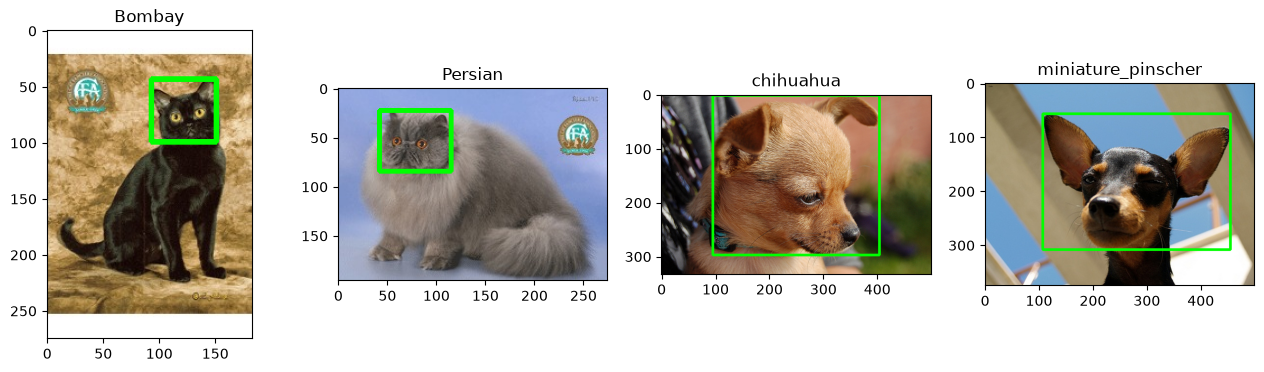

In [14]:
breeds = variant_info["breeds"]
plt.figure(figsize=(16, 4))
for i, breed in enumerate(breeds):
    name = info[(info["breed"] == breed) & info["has_xml"]]["filename"].iloc[0]
    img = cv2.cvtColor(cv2.imread(str(IMG_DIR / name)), cv2.COLOR_BGR2RGB)
    for x0, y0, x1, y1 in read_boxes(XML_DIR / (Path(name).stem + ".xml")):
        cv2.rectangle(img, (x0, y0), (x1, y1), (0, 255, 0), 3)
    plt.subplot(1, len(breeds), i + 1); plt.imshow(img); plt.title(breed)
plt.savefig(RESULTS / "samples_grid.png", dpi=110)
plt.show()

## 5. Числа для отчёта и выгрузка

Напечатайте всё, что понадобится в README. Затем упакуйте `results/` в архив и скачайте:
- в Kaggle: правая панель → Output → `results.zip` → Download; ноутбук: File → Download Notebook;
- в Colab: архив скачается сам после запуска ячейки; ноутбук: File → Download → Download .ipynb;
- локально: ничего скачивать не нужно, всё уже лежит в папке `lab01/`.

Переименуйте скачанный ноутбук в `solution.ipynb`.

In [15]:
print(summary_df.to_string(index=False))

expected = {"summary.csv", "transforms.png", "samples_grid.png"}
missing = expected - {p.name for p in RESULTS.iterdir()}
print("не хватает:", missing if missing else "ничего, все 3 файла на месте")

        metric  value
       variant   17.0
       n_files  800.0
      n_breeds    4.0
        n_cats  400.0
        n_dogs  400.0
     width_min  114.0
  width_median  375.0
     width_max 1725.0
    height_min  103.0
 height_median  333.0
    height_max 1600.0
     n_not_rgb    0.0
n_jpg_not_jpeg    0.0
    n_with_xml  400.0
не хватает: ничего, все 3 файла на месте


In [16]:
import shutil
if ENV != "local":
    archive = shutil.make_archive("results", "zip", RESULTS)
    print("архив:", archive)
    if ENV == "colab":
        from google.colab import files
        files.download(archive)